# Credits

## Import and read file

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

In [2]:
root = '../data'

In [3]:
credits = pd.read_csv(root + '/credits.csv', converters={'cast': ast.literal_eval, 'crew': ast.literal_eval}) # converters were added after inspection

print(f"There are {credits.shape[0]} rows and {credits.shape[1]} columns in the credits dataset")

display(credits.head())

There are 45476 rows and 3 columns in the credits dataset


,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': 'Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


## id

In [4]:
# check for na values
print(f"Nr of rows with no id: {credits.id.isna().sum()}")

# check whether id is unique
id_vc = credits.id.value_counts()
print(f"There are {credits.id.duplicated().sum()} duplicate rows, among which the highest number of duplicates for one id is {id_vc.iloc[0]} which occurs {(id_vc == id_vc.iloc[0]).sum()} time")

# compare the duplicate rows, the lists are converted to strings so they can be compared
duplicate_ids = credits[credits.id.duplicated(keep=False)]
duplicate_str = duplicate_ids.astype(str)
print(f"Nr of duplicate rows that are identical copies: {duplicate_str.duplicated().sum()}")

# columns where the duplicates differ
differs = duplicate_str.groupby('id').nunique().gt(1)
display(differs.sum().rename('differing_columns'))

# the crew lists that differ contain the same members, only in a different order
same_members = duplicate_ids.groupby('id').crew.agg(lambda crews: len({tuple(sorted(map(str, crew))) for crew in crews}) == 1)
print(f"Duplicate ids where the crew contains the same members, but in a different order: {same_members.sum()} of {len(same_members)}")

Nr of rows with no id: 0
There are 44 duplicate rows, among which the highest number of duplicates for one id is 3 which occurs 1 time
Nr of duplicate rows that are identical copies: 37


cast    0
crew    7
Name: differing_columns, dtype: int64

Duplicate ids where the crew contains the same members, but in a different order: 43 of 43


In [5]:
# compare with the ids in movies_metadata, ids that cannot be read as numbers come from the wrongfully split rows
mm_ids = pd.to_numeric(pd.read_csv(root + '/movies_metadata.csv', usecols=['id'], dtype=str).id, errors='coerce').dropna().astype(int)
print(f"Nr of movies in credits that are not in movies_metadata: {(~credits.id.isin(mm_ids)).sum()}")
print(f"Nr of movies in movies_metadata that are not in credits: {(~mm_ids.drop_duplicates().isin(credits.id)).sum()}, id: {mm_ids[~mm_ids.isin(credits.id)].tolist()}")

Nr of movies in credits that are not in movies_metadata: 0
Nr of movies in movies_metadata that are not in credits: 1, id: [401840]


In [6]:
# all duplicates hold the same cast and crew, so the first row is kept to avoid counting the same credits twice
credits = credits.drop_duplicates('id')
print(f"There are {credits.shape[0]} rows after removing duplicate ids")

There are 45432 rows after removing duplicate ids


## cast

In [7]:
def explode(df, column_names):
    exploded = df.explode().dropna()
    df_exploded = pd.DataFrame()
    for column_name in column_names:
        df_exploded[column_name] = exploded.apply(lambda x: x[column_name])
    df_exploded['movie_id'] = credits.id.loc[exploded.index].to_numpy() # keep which movie the credit belongs to
    return df_exploded

# find keys
keys = credits.cast.iloc[0][0].keys()
exploded_cast = explode(credits.cast, keys)
display(exploded_cast.head())

# check unique ids
exploded_cast.id.describe()
print(f"There are {len(exploded_cast.id.unique())} ({len(exploded_cast.id.unique())/len(exploded_cast.id):.1%}) unique ids")

# it appears that id is per actor
# display(exploded_cast[exploded_cast['name'] == 'Tom Hanks'])

# ids that map to more than one name
names_per_id = exploded_cast.groupby('id')['name'].nunique()
dup_ids = names_per_id[names_per_id > 1].index
print(f"Nr of ids with multiple names: {len(dup_ids)}")
display(exploded_cast.loc[exploded_cast.id.isin(dup_ids), ['id', 'name']].drop_duplicates().sort_values(['id', 'name']))

# names that map to more than one id
ids_per_name = exploded_cast.groupby(['name'])['id'].nunique()
dup_names = ids_per_name[ids_per_name > 1].index
print(f"Nr of names with multiple ids: {len(dup_names)}")
display(exploded_cast.loc[exploded_cast.name.isin(dup_names), ['name', 'id']].drop_duplicates().sort_values(['name', 'id']).head(6))

# so it cannot be decided from the data whether they are different people or duplicate TMDB entries
display(exploded_cast[exploded_cast.name.isin(['Aaron Harrison', 'Aaron Jackson'])][['name', 'id', 'gender', 'movie_id', 'character', 'profile_path']].sort_values(['name', 'id']))


,cast_id,character,credit_id,gender,id,name,order,profile_path,movie_id
0,14,Woody (voice),52fe4284c3a36847f8024f95,2,31,Tom Hanks,0,/pQFoyx7rp09CJTAb932F2g8Nlho.jpg,862
0,15,Buzz Lightyear (voice),52fe4284c3a36847f8024f99,2,12898,Tim Allen,1,/uX2xVf6pMmPepxnvFWyBtjexzgY.jpg,862
0,16,Mr. Potato Head (voice),52fe4284c3a36847f8024f9d,2,7167,Don Rickles,2,/h5BcaDMPRVLHLDzbQavec4xfSdt.jpg,862
0,17,Slinky Dog (voice),52fe4284c3a36847f8024fa1,2,12899,Jim Varney,3,/eIo2jVVXYgjDtaHoF19Ll9vtW7h.jpg,862
0,18,Rex (voice),52fe4284c3a36847f8024fa5,2,12900,Wallace Shawn,4,/oGE6JqPP2xH4tNORKNqxbNPYi7u.jpg,862


There are 206158 (36.7%) unique ids
Nr of ids with multiple names: 14


,id,name
42005,9779,Morris Chestnut
201,9779,Моррис Честнат
45473,23764,Erika Eleniak
291,23764,Эрика Элениак
45473,58646,Damian Chapa
388,58646,Дэмиан Чапа
42225,67212,Tom Wu
6018,67212,Том Ву
39559,72932,Ryuhei Matsuda
8076,72932,松田龙平


Nr of names with multiple ids: 3053


,name,id
38225,Aaron Harrison,459878
15977,Aaron Harrison,1200414
6857,Aaron Jackson,20633
20570,Aaron Jackson,1435850
24342,Aaron Jackson,1780265
6352,Aaron Jeffery,92172


,name,id,gender,movie_id,character,profile_path
38225,Aaron Harrison,459878,0,76164,Cop Zombie,None
15977,Aaron Harrison,1200414,0,42941,Emil,None
6857,Aaron Jackson,20633,0,2007,Francesco Odone,None
20570,Aaron Jackson,1435850,0,127372,Lt Col. Rogers,None
39347,Aaron Jackson,1435850,0,294272,Abner,None
24342,Aaron Jackson,1780265,0,246741,Club Bouncer,None


In [8]:
# inspect gender, the values are TMDB codes: 0 = not specified, 1 = female, 2 = male
# (TMDB later added 3 = non-binary, which does not occur in this dataset)
display(exploded_cast.gender.value_counts())

# gender per actor rather than per role
display(exploded_cast.drop_duplicates('id').gender.value_counts())

# actors that are registered with different gender in different movies
gender_per_id = exploded_cast.groupby('id')['gender'].nunique()
multi_gender = gender_per_id[gender_per_id > 1].index
print(f"Nr of ids with multiple genders: {len(multi_gender)}")
display(exploded_cast[exploded_cast.id.isin(multi_gender)]
        .groupby('id')
        .agg(name=('name', 'first'), genders=('gender', lambda g: g.value_counts().to_dict())))


gender
2    226555
0    223765
1    111724
Name: count, dtype: int64

gender
0    142019
2     38396
1     25743
Name: count, dtype: int64

Nr of ids with multiple genders: 11


,name,genders
id,,
4644,Semka Sokolović-Bertok,"{0: 1, 1: 1}"
17199,Corey Johnson,"{0: 22, 2: 4}"
47395,Miles Malleson,"{2: 18, 0: 10}"
70883,Tusse Silberg,"{0: 4, 1: 1}"
78809,Рашад Эванс,"{2: 2, 0: 1}"
114733,Kan Tokumaru,"{0: 2, 2: 1}"
191752,Georgie Glen,"{0: 5, 1: 1}"
935841,Joe B. Barton,"{0: 1, 2: 1}"
1135277,Aleksander Sewruk,"{0: 1, 2: 1}"


There are 2414 (5.3%) movies with no cast


count    45432.000000
mean        12.371104
std         12.089791
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        313.000000
Name: cast, dtype: float64

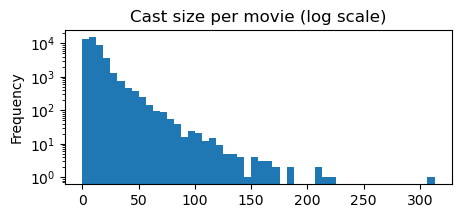

Nr of duplicate credit ids: 0
Nr of rows where the actor already appears in the same movie: 1207
Nr of rows where the actor already appears in the same movie with the same character: 4


,movie_id,name,character,order
70,11859,Dan Hedaya,,15
70,11859,Dan Hedaya,Walter Hollenbach (uncredited),17
85,10534,David Lascher,Robert Marsh,6
85,10534,David Lascher,Robert March,7


In [9]:
# nr of movies without cast and number of actors per movie
cast_size = credits.cast.str.len()
print(f"There are {(cast_size == 0).sum()} ({(cast_size == 0).mean():.1%}) movies with no cast")
display(cast_size.describe())
cast_size.plot.hist(bins=50, figsize=(5, 2), title='Cast size per movie (log scale)', logy=True)
plt.show()

# credit_id should identify one role in one movie
print(f"Nr of duplicate credit ids: {exploded_cast.credit_id.duplicated().sum()}")

# actors with several roles in the same movie
print(f"Nr of rows where the actor already appears in the same movie: {exploded_cast.duplicated(['movie_id', 'id']).sum()}")
print(f"Nr of rows where the actor already appears in the same movie with the same character: {exploded_cast.duplicated(['movie_id', 'id', 'character']).sum()}")
display(exploded_cast[exploded_cast.duplicated(['movie_id', 'id'], keep=False)][['movie_id', 'name', 'character', 'order']].head(4))

In [10]:
# check the billing order, it is expected to go from 0 to the number of actors - 1 in every movie
display(exploded_cast.order.describe())
order = exploded_cast.groupby('movie_id')['order'].agg(['min', 'max', 'size'])
print(f"Nr of movies where order does not start at 0: {(order['min'] != 0).sum()} ({(order['min'] != 0).mean():.1%})")
print(f"Nr of movies with gaps in order: {(order['max'] + 1 != order['size']).sum()} ({(order['max'] + 1 != order['size']).mean():.1%})")

count    562044.000000
mean         11.848889
std          16.009755
min           0.000000
25%           3.000000
50%           7.000000
75%          14.000000
max         313.000000
Name: order, dtype: float64

Nr of movies where order does not start at 0: 6314 (14.7%)
Nr of movies with gaps in order: 11399 (26.5%)


In [11]:
# discover formatting errors in the string columns
for column_name in ['name', 'character']:
    c = exploded_cast[column_name]
    print(f"{column_name}: {(c == '').sum()} empty, {(c != c.str.strip()).sum()} with leading/trailing spaces, {c.str.contains('  ').sum()} with double spaces")

# most frequent characters, Himself/himself shows that the case is not consistent
display(exploded_cast.character.value_counts().head(8))

print(f"There are {exploded_cast.profile_path.isna().sum()} ({exploded_cast.profile_path.isna().mean():.1%}) rows with no profile path")

name: 0 empty, 490 with leading/trailing spaces, 57 with double spaces
character: 25766 empty, 1 with leading/trailing spaces, 103 with double spaces


character
            25766
Himself     11431
Herself      3068
Doctor        663
Dancer        583
Narrator      561
Reporter      545
himself       542
Name: count, dtype: int64

There are 173678 (30.9%) rows with no profile path


## crew

In [12]:
# find keys
keys = credits.crew.iloc[0][0].keys()
display(keys)

exploded_crew = explode(credits.crew, keys)
display(exploded_crew.head())

dict_keys(['credit_id', 'department', 'gender', 'id', 'job', 'name', 'profile_path'])

,credit_id,department,gender,id,job,name,profile_path,movie_id
0,52fe4284c3a36847f8024f49,Directing,2,7879,Director,John Lasseter,/7EdqiNbr4FRjIhKHyPPdFfEEEFG.jpg,862
0,52fe4284c3a36847f8024f4f,Writing,2,12891,Screenplay,Joss Whedon,/dTiVsuaTVTeGmvkhcyJvKp2A5kr.jpg,862
0,52fe4284c3a36847f8024f55,Writing,2,7,Screenplay,Andrew Stanton,/pvQWsu0qc8JFQhMVJkTHuexUAa1.jpg,862
0,52fe4284c3a36847f8024f5b,Writing,2,12892,Screenplay,Joel Cohen,/dAubAiZcvKFbboWlj7oXOkZnTSu.jpg,862
0,52fe4284c3a36847f8024f61,Writing,0,12893,Screenplay,Alec Sokolow,/v79vlRYi94BZUQnkkyznbGUZLjT.jpg,862


There are 771 (1.7%) movies with no crew
There are 421 (0.9%) movies with neither cast nor crew


count    45432.000000
mean        10.209456
std         15.804910
min          0.000000
25%          2.000000
50%          6.000000
75%         12.000000
max        435.000000
Name: crew, dtype: float64

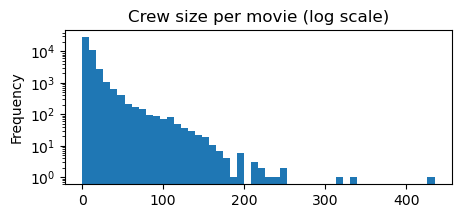

In [13]:
# nr of movies without crew and number of crew members per movie
crew_size = credits.crew.str.len()
print(f"There are {(crew_size == 0).sum()} ({(crew_size == 0).mean():.1%}) movies with no crew")
print(f"There are {((crew_size == 0) & (cast_size == 0)).sum()} ({((crew_size == 0) & (cast_size == 0)).mean():.1%}) movies with neither cast nor crew")
display(crew_size.describe())
crew_size.plot.hist(bins=50, figsize=(5, 2), title='Crew size per movie (log scale)', logy=True)
plt.show()

In [14]:
# inspect department and job
display(exploded_crew.department.value_counts())
print(f"There are {exploded_crew.job.nunique()} unique jobs")
display(exploded_crew.job.value_counts().head(10))

# jobs that belong to more than one department
departments_per_job = exploded_crew.groupby('job')['department'].nunique()
display(departments_per_job[departments_per_job > 1])

# the department Actors is unexpected in crew
display(exploded_crew[exploded_crew.department == 'Actors'].job.value_counts())

department
Production           94401
Writing              74759
Directing            58073
Sound                50548
Art                  40652
Camera               33506
Crew                 31572
Costume & Make-Up    30823
Editing              29795
Visual Effects       14842
Lighting              4846
Actors                  19
Name: count, dtype: int64

There are 456 unique jobs


job
Director                   48999
Producer                   43507
Writer                     30398
Screenplay                 25143
Editor                     23770
Director of Photography    20640
Executive Producer         18853
Original Music Composer    15773
Casting                    12620
Art Direction              11679
Name: count, dtype: int64

job
Art Direction                2
Dialogue Editor              2
Digital Effects Producer     2
Other                       10
Property Master              2
Sound Recordist              2
Supervising Art Director     2
Unit Production Manager      2
Name: department, dtype: int64

job
Actor           9
Stunt Double    8
Voice           2
Name: count, dtype: int64

In [15]:
# directors per movie
directors = exploded_crew[exploded_crew.job == 'Director'].groupby('movie_id').size()
print(f"There are {(~credits.id.isin(directors.index)).sum()} movies without a director")
display(directors.describe())

# credit_id should identify one job in one movie
print(f"Nr of duplicate credit ids: {exploded_crew.credit_id.duplicated().sum()}")

# crew members with several jobs in the same movie (e.g. director and writer)
print(f"Nr of rows where the person already appears in the same movie: {exploded_crew.duplicated(['movie_id', 'id']).sum()}")
print(f"Nr of rows where the person already appears in the same movie with the same job: {exploded_crew.duplicated(['movie_id', 'id', 'job']).sum()}")

There are 887 movies without a director


count    44545.000000
mean         1.099989
std          0.616294
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         42.000000
dtype: float64

Nr of duplicate credit ids: 0
Nr of rows where the person already appears in the same movie: 41034
Nr of rows where the person already appears in the same movie with the same job: 0


In [16]:
# inspect gender
display(exploded_crew.gender.value_counts())
# gender per person rather than per job
display(exploded_crew.drop_duplicates('id').gender.value_counts())

# share of each gender per department
display(pd.crosstab(exploded_crew.department, exploded_crew.gender, normalize='index').round(2))

gender_per_id = exploded_crew.groupby('id')['gender'].nunique()
print(f"Nr of ids with multiple genders: {(gender_per_id > 1).sum()}")

gender
0    272032
2    160711
1     31093
Name: count, dtype: int64

gender
0    130111
2     25120
1      6344
Name: count, dtype: int64

gender,0,1,2
department,,,
Actors,0.58,0.11,0.32
Art,0.65,0.07,0.28
Camera,0.55,0.01,0.44
Costume & Make-Up,0.76,0.15,0.09
Crew,0.79,0.02,0.19
Directing,0.45,0.05,0.49
Editing,0.57,0.07,0.36
Lighting,0.91,0.00,0.09
Production,0.51,0.13,0.36


Nr of ids with multiple genders: 2


In [17]:
# ids that map to more than one name
names_per_id = exploded_crew.groupby('id')['name'].nunique()
dup_ids = names_per_id[names_per_id > 1].index
print(f"Nr of ids with multiple names: {len(dup_ids)}")
display(exploded_crew.loc[exploded_crew.id.isin(dup_ids), ['id', 'name']].drop_duplicates())

# names that map to more than one id
ids_per_name = exploded_crew.groupby('name')['id'].nunique()
print(f"Nr of names with multiple ids: {(ids_per_name > 1).sum()}")

# discover formatting errors
c = exploded_crew.name
print(f"name: {(c == '').sum()} empty, {(c != c.str.strip()).sum()} with leading/trailing spaces, {c.str.contains('  ').sum()} with double spaces")
print(f"There are {exploded_crew.profile_path.isna().sum()} ({exploded_crew.profile_path.isna().mean():.1%}) rows with no profile path")

Nr of ids with multiple names: 1


,id,name
2511,63574,Ka-Fai Cheung
9700,63574,Cheung Ka-Fai


Nr of names with multiple ids: 3369
name: 0 empty, 550 with leading/trailing spaces, 51 with double spaces
There are 368835 (79.5%) rows with no profile path


## cast and crew combined

In [18]:
# persons are identified by the same id in cast and crew
print(f"Nr of persons that appear in both cast and crew: {len(set(exploded_cast.id) & set(exploded_crew.id))}")
print(f"Nr of credit ids that appear in both cast and crew: {len(set(exploded_cast.credit_id) & set(exploded_crew.credit_id))}")

persons = pd.concat([exploded_cast[['id', 'name', 'gender']], exploded_crew[['id', 'name', 'gender']]])
print(f"There are {persons.id.nunique()} unique persons")
print(f"Nr of ids with multiple names: {(persons.groupby('id')['name'].nunique() > 1).sum()}")
print(f"Nr of names with multiple ids: {(persons.groupby('name')['id'].nunique() > 1).sum()}")
print(f"Nr of ids with multiple genders: {(persons.groupby('id')['gender'].nunique() > 1).sum()}")

Nr of persons that appear in both cast and crew: 14390
Nr of credit ids that appear in both cast and crew: 0
There are 353343 unique persons
Nr of ids with multiple names: 15
Nr of names with multiple ids: 8347
Nr of ids with multiple genders: 12


## Conclusion

## Findings and decisions

| Finding | Decision |
|---|---|
|The file loads cleanly with 45,476 rows and 3 columns (`cast`, `crew`, `id`). `cast` and `crew` are stored as strings of Python lists of dictionaries and have to be parsed with `ast.literal_eval`. Every cast entry has the same 8 keys and every crew entry the same 7 keys.|No action needed|
|`id` has no missing values, but it is not unique: 43 ids occur more than once (44 surplus rows, one id three times). 37 of the surplus rows are exact copies. In the remaining 7 the crew members are the same, only listed in a different order. All movies in credits exist in movies_metadata, while one movie in movies_metadata (id 401840) has no credits. | All duplicates can be removed by keeping the first row.|
|15 person ids have several names (14 in cast, 1 in crew). These are the same name written in another script. It appears to be the same name bit in a different language. On inspection it appears as the higher index represent the name using latin letters|Keep last occurence of the names|
|3,053 names in cast and 3,369 in crew map to several ids|Keep as there could be different people with common names|
|`gender` uses TMDB's codes: `0` = not specified, `1` = female, `2` = male. 11 ids have different genders in different movies, in all cases `0` in some movies and a known value in others. The known value should be used.|Keep the non-zero value|
|1,207 rows (0.2 %) are an actor appearing more than once in the same movie, mostly playing several characters. Only 4 have the same character twice.|Remove the duplicate appearance. We do not store character in the final collection so we won't loose information even where they play the same character|
|`order` (billing order) does not start at 0 in 6,314 movies (14.7 %) and has gaps in 11,399 movies (26.5 %). It can be used to rank the actors within a movie, but not as a position.|No action needed|
|- `name` has 490 values with leading/trailing spaces and 57 with double spaces. `character` has 103 with double spaces, and the case is not consistent, e.g. *Himself* (11,431) and *himself* (542).|No action needed|
|There are 887 movies without a direction, most movies have one director and the maximum number of directors is 42|No action needed|

**Missing values (often hidden as `0`, `''` or `[]`)**

| Column | Encoded as | Rows |
|---|---|---|
| `cast` | `[]` | 2,414 movies (5.3 %) |
| `crew` | `[]` | 771 movies (1.7 %) |
| `cast` and `crew` | both `[]` | 421 movies (0.9 %) |
| director in `crew` | no `Director` job | 887 movies (2.0 %) |
| cast `gender` | `0` | 223,765 roles (39.8 %) / 142,019 actors (68.9 %) |
| crew `gender` | `0` | 272,032 jobs (58.6 %) / 130,111 persons (80.5 %) |
| cast `character` | `''` | 25,766 (4.6 %) |
| cast `profile_path` | `None` | 173,678 (30.9 %) |
| crew `profile_path` | `None` | 368,835 (79.5 %) |
